In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import emcee
import corner
from IPython.display import display, Math
from numba import njit
from dynesty import NestedSampler

In [2]:
from values.metrics import metrics
from values.binary_data import name_binary
from analysis.qpo_analysis import calc_freq
from analysis.qpo_analysis import f_U_err_direct
from analysis.qpo_analysis import f_L_err_direct
from models.REG_no_bias_prior import get_L_BH
from models.REG_no_bias_prior import get_L_best
from models.REG_no_bias_prior import get_radii
from models.REG_no_bias_prior import log_posterior_probability
from models.REG_no_bias_prior import prepare_mcmc_samples
from models.REG_no_bias_prior import ptform
from models.REG_no_bias_prior import log_likelihood_dynesty
from models.REG_no_bias_prior import ISCOs_dynesty

In [3]:
f_U_func,f_U_err_func,f_L_func,f_L_err_func,V_2diff,f,f_diff = calc_freq(metrics["h_REG"])

In [4]:
L_BH = get_L_BH(f)
L_max = 5*np.asarray(L_BH)
L_best = get_L_best(f_U_func,f_L_func,V_2diff,f,f_diff,L_max)
r_best,ISCOs = get_radii(f_U_func,f_L_func,V_2diff,f,f_diff,L_max)

for i in range(len(L_BH)):
    display(Math(rf"L_{{\mathrm{{max}},{i}}} = {L_BH[i]:.3f} \mathrm{{m}}"))
    display(Math(rf"L_{{\mathrm{{best}},{i}}} = {L_best[i]:.3f} \mathrm{{m}}"))
    display(Math(rf"r_{{best,{i}}} = {r_best[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (5 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [5]:
chi_summary=np.round(np.array(L_best+r_best)/1000,2)

In [6]:
labels = ["L_0", "L_1", "L_2", "L_3", "L_4", "r_0", "r_1", "r_2", "r_3", "r_4"]

In [7]:
n_walkers = 32
n_dim = len(L_best+r_best)
n_steps = 50000
pos = L_best+r_best - (np.random.randn(n_walkers, n_dim))

f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)

#nwalkers, ndim = pos.shape
sampler = emcee.EnsembleSampler(
    n_walkers, n_dim, log_posterior_probability, args=(f_U_func, f_U_err_direct_numba, f_L_func, f_L_err_direct_numba, V_2diff, f_diff, L_max, ISCOs, L_BH) 
)
sampler.run_mcmc(pos, n_steps, progress=True)

100%|██████████| 50000/50000 [01:06<00:00, 746.34it/s]


State([[  9298.09889593   4759.39389023  23900.5508813   16218.57873198
   14143.87076518  43816.33493483  81624.39828187  70588.10219808
   74631.09774804 118322.94691581]
 [ 10866.76825548   3545.1724093   30892.51916098  17536.08253419
    2656.73447433  45070.82287     81752.64481564  71768.04380016
   74529.61553864 115034.45303193]
 [  9874.83468728   6809.90533553  29302.02316529  18760.98629204
   17007.41184759  44562.21901397  83109.24179753  83807.75830884
   72996.73587239 113673.25115854]
 [  9832.11760007    635.41421271  28255.50839794  18392.14772308
    2016.71878383  43562.30575167  78503.0429614   76832.27745093
   73049.91623472 119616.53583989]
 [ 10471.59999752   6195.89655931  17524.66798758  18388.73565631
   11148.87204863  45259.72930938  80135.2773306   92223.73289031
   72219.07729921 125168.69442609]
 [  8927.15734801   1784.52686262  24263.62203506  21365.06688129
    1589.02825646  44292.16972883  81062.03122022  80530.82089802
   70403.65581659 116907.84

(50000, 32, 10)


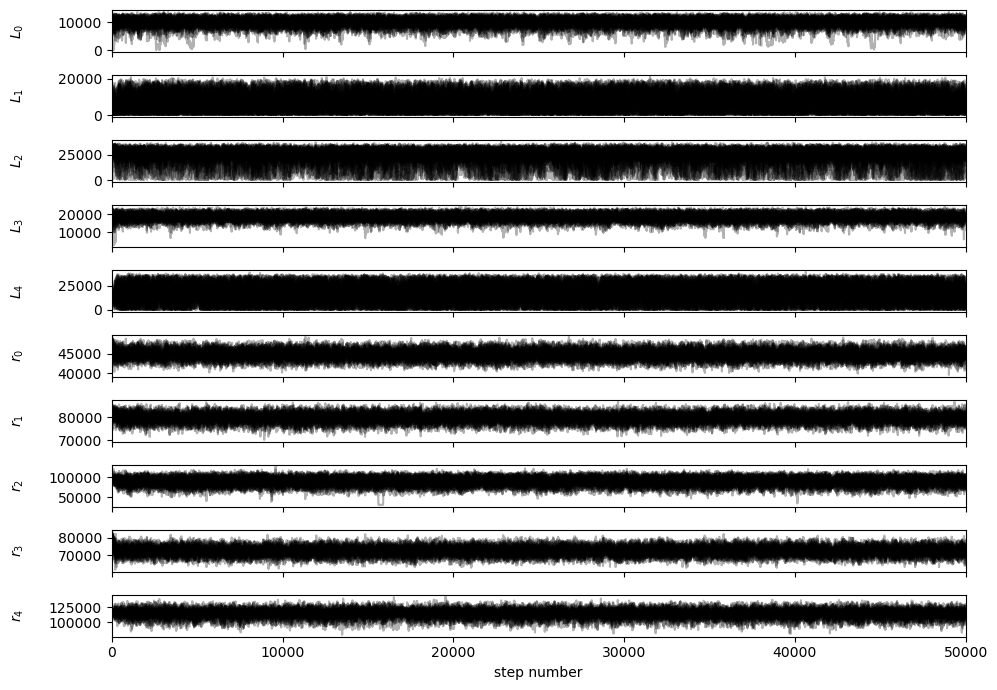

In [8]:
fig, axes = plt.subplots(n_dim, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
print(samples.shape)
for i in range(n_dim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))

    ax.set_ylabel(fr"${labels[i]}$")
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.tight_layout()

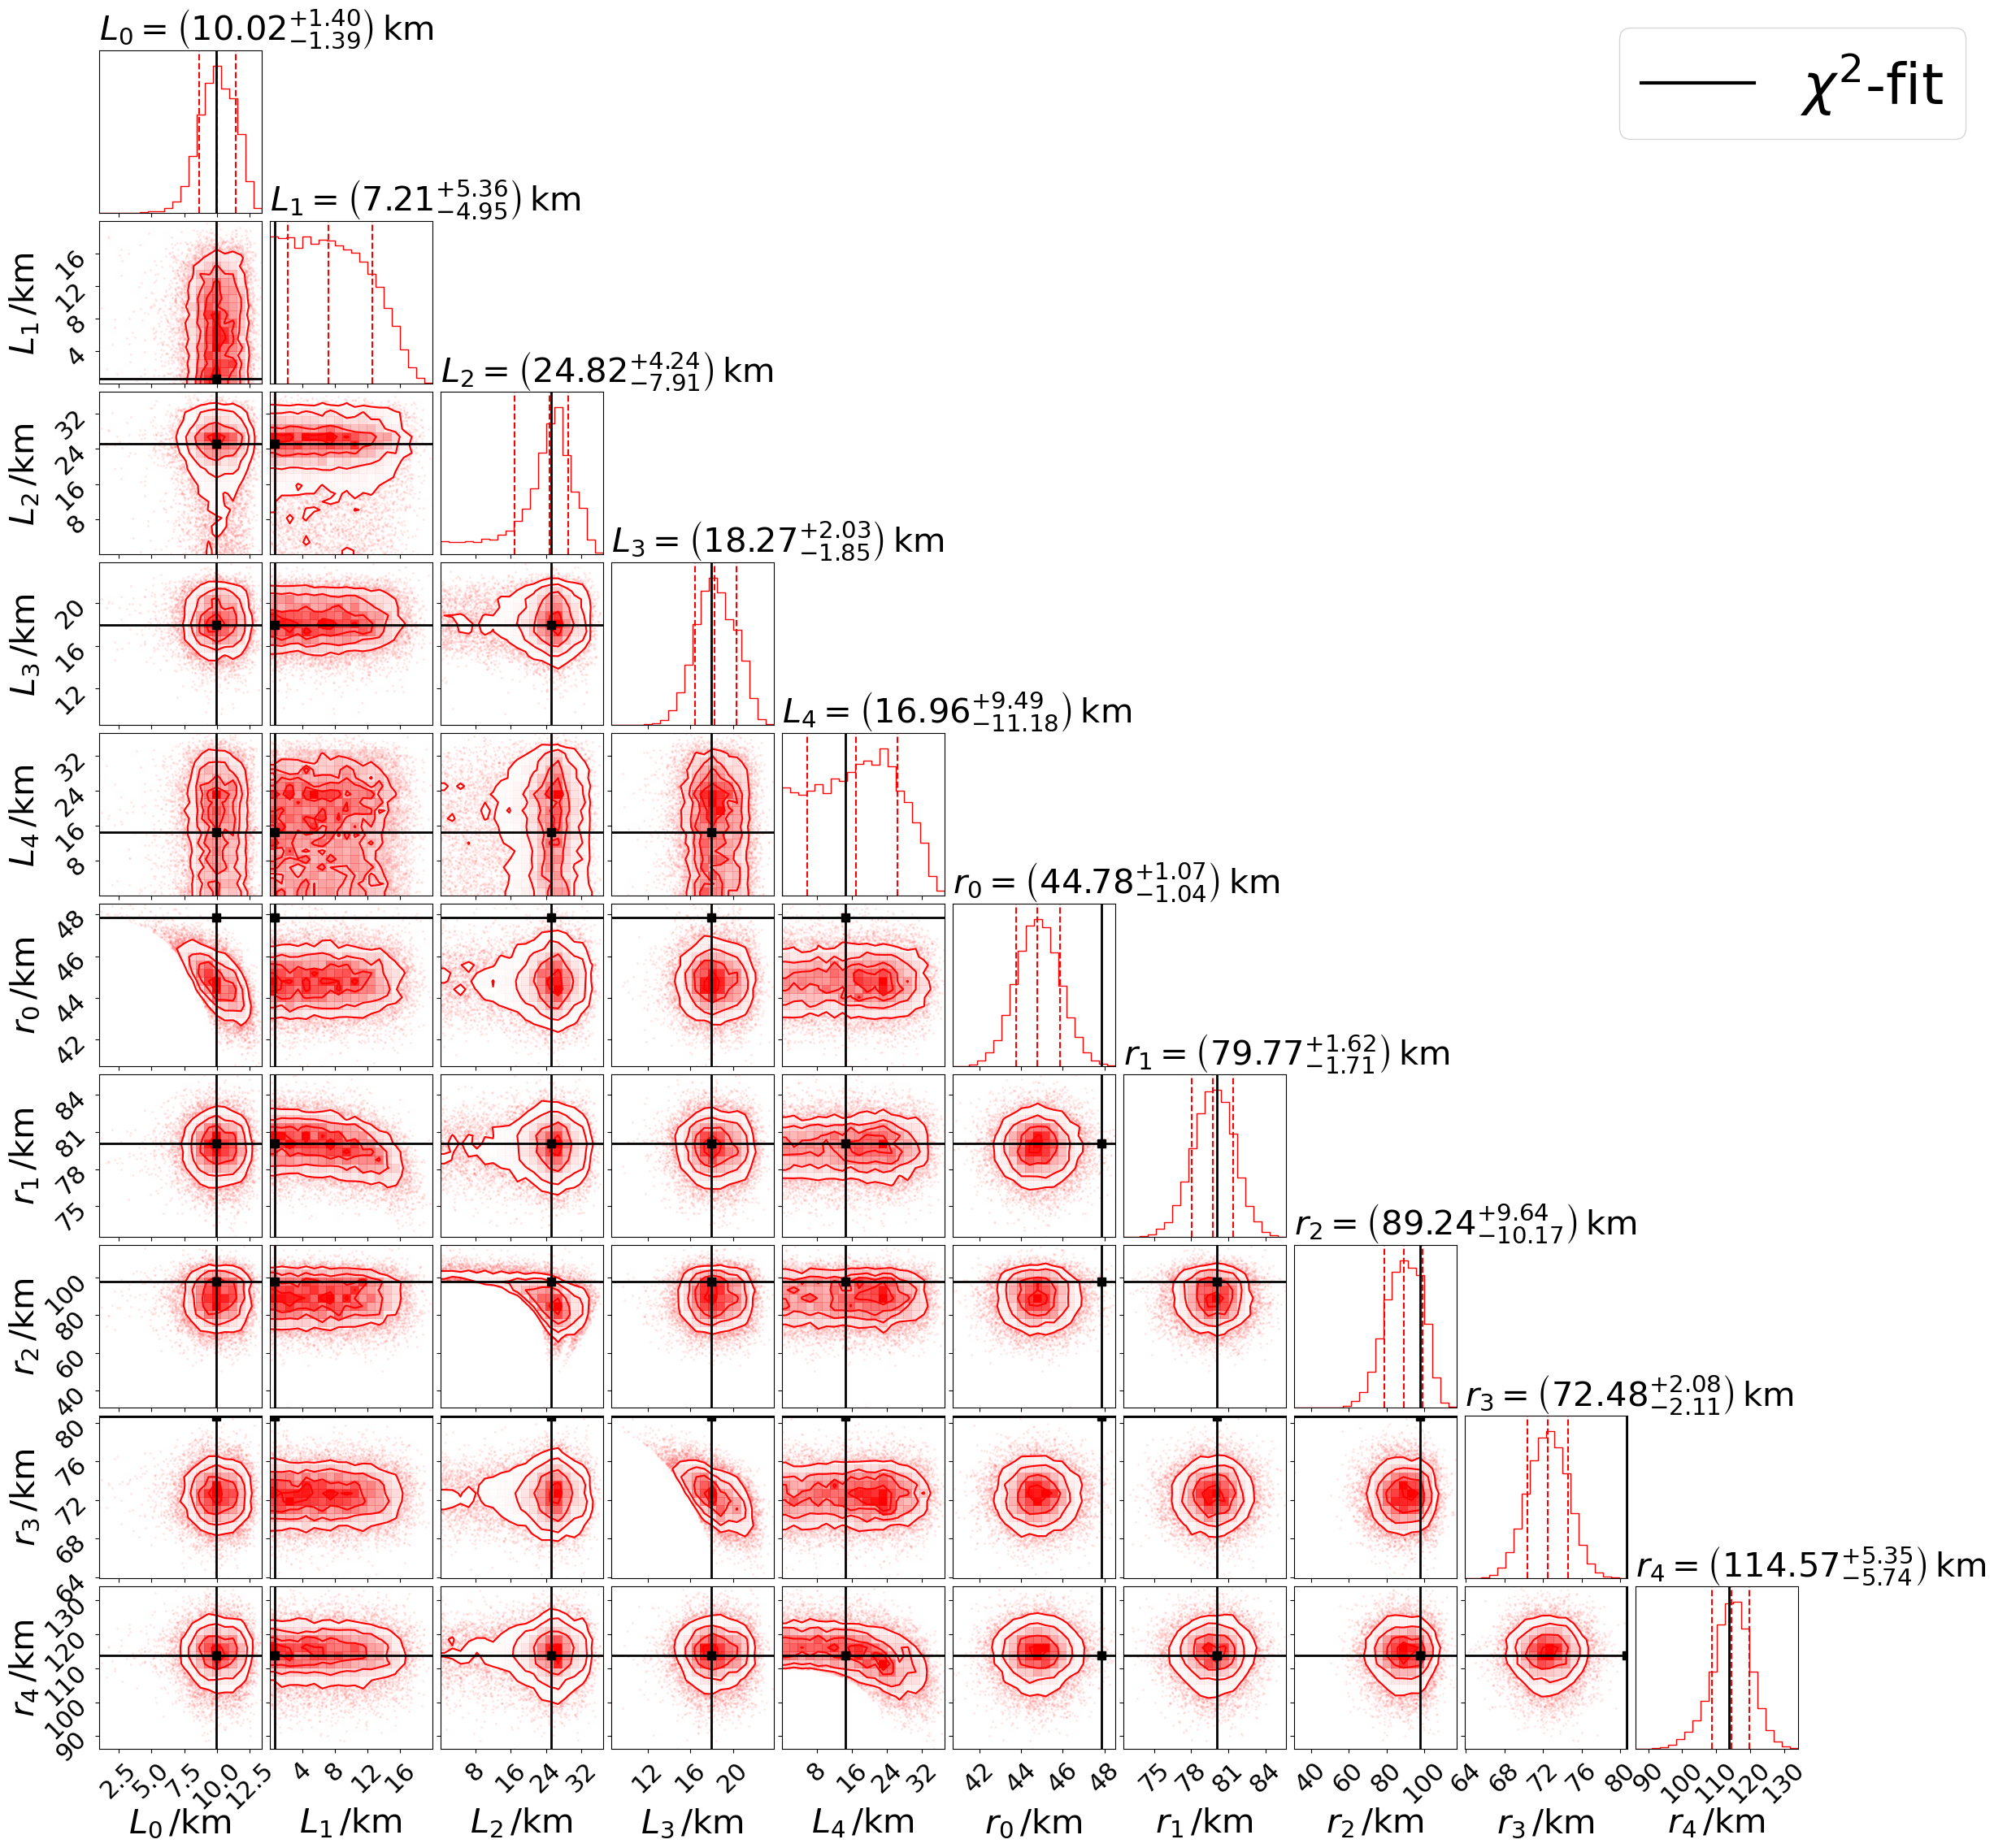

In [9]:
plt.rcParams.update({'font.size': 50,'xtick.labelsize': 22,'ytick.labelsize': 22})
flat_samples = prepare_mcmc_samples(sampler)
fig = corner.corner(
    flat_samples/1000, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 30},color="red",labelpad=0.05
)

mcmc_quantiles = np.array([corner.quantile(flat_samples[:, i],(0.16, 0.5, 0.84))for i in range(flat_samples.shape[1])])
mcmc_summary = np.column_stack((np.round(mcmc_quantiles[:, 1]/1000,2),np.round((mcmc_quantiles[:, 0] - mcmc_quantiles[:, 1])/1000,2),np.round((mcmc_quantiles[:, 2] - mcmc_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(n_dim, n_dim)

for i, label in enumerate(labels):
    mcmc_title = (
        rf"${label} = "
        rf"\left({mcmc_summary[:,0][i]:.2f}"
        rf"^{{+{mcmc_summary[:,2][i]:.2f}}}_{{{mcmc_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(mcmc_title,fontsize=30,loc="left",)
truths=np.array(L_best+r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
fig.legend(handles=[legend_line])

plt.savefig("../results/h_REG_mcmc_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

In [10]:
values = []
for i in range(n_dim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)
    txt = "\mathrm{{{3}}} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], labels[i])
    display(Math(txt))
    values.append(mcmc[1])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
ndim = len(L_best+r_best)
f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)
ISCOs_dyn = ISCOs_dynesty(V_2diff,f,f_diff)

dyn_sampler = NestedSampler(log_likelihood_dynesty, ptform, ndim, logl_args=(f_U_func, f_U_err_direct_numba, f_L_func,f_L_err_direct_numba), ptform_args=(V_2diff, f_diff, L_max, ISCOs_dyn, L_BH),nlive = 1000, sample="rslice")

dyn_sampler.run_nested()

100%|█████████▉| 25812/25813 [01:22<00:00, 314.18it/s, +1000 | bound: 128 | nc: 1 | ncall: 1649881 | eff(%):  1.626 | loglstar: -42.756 | logz: -68.809 | dlogz:  0.001 >  1.009]


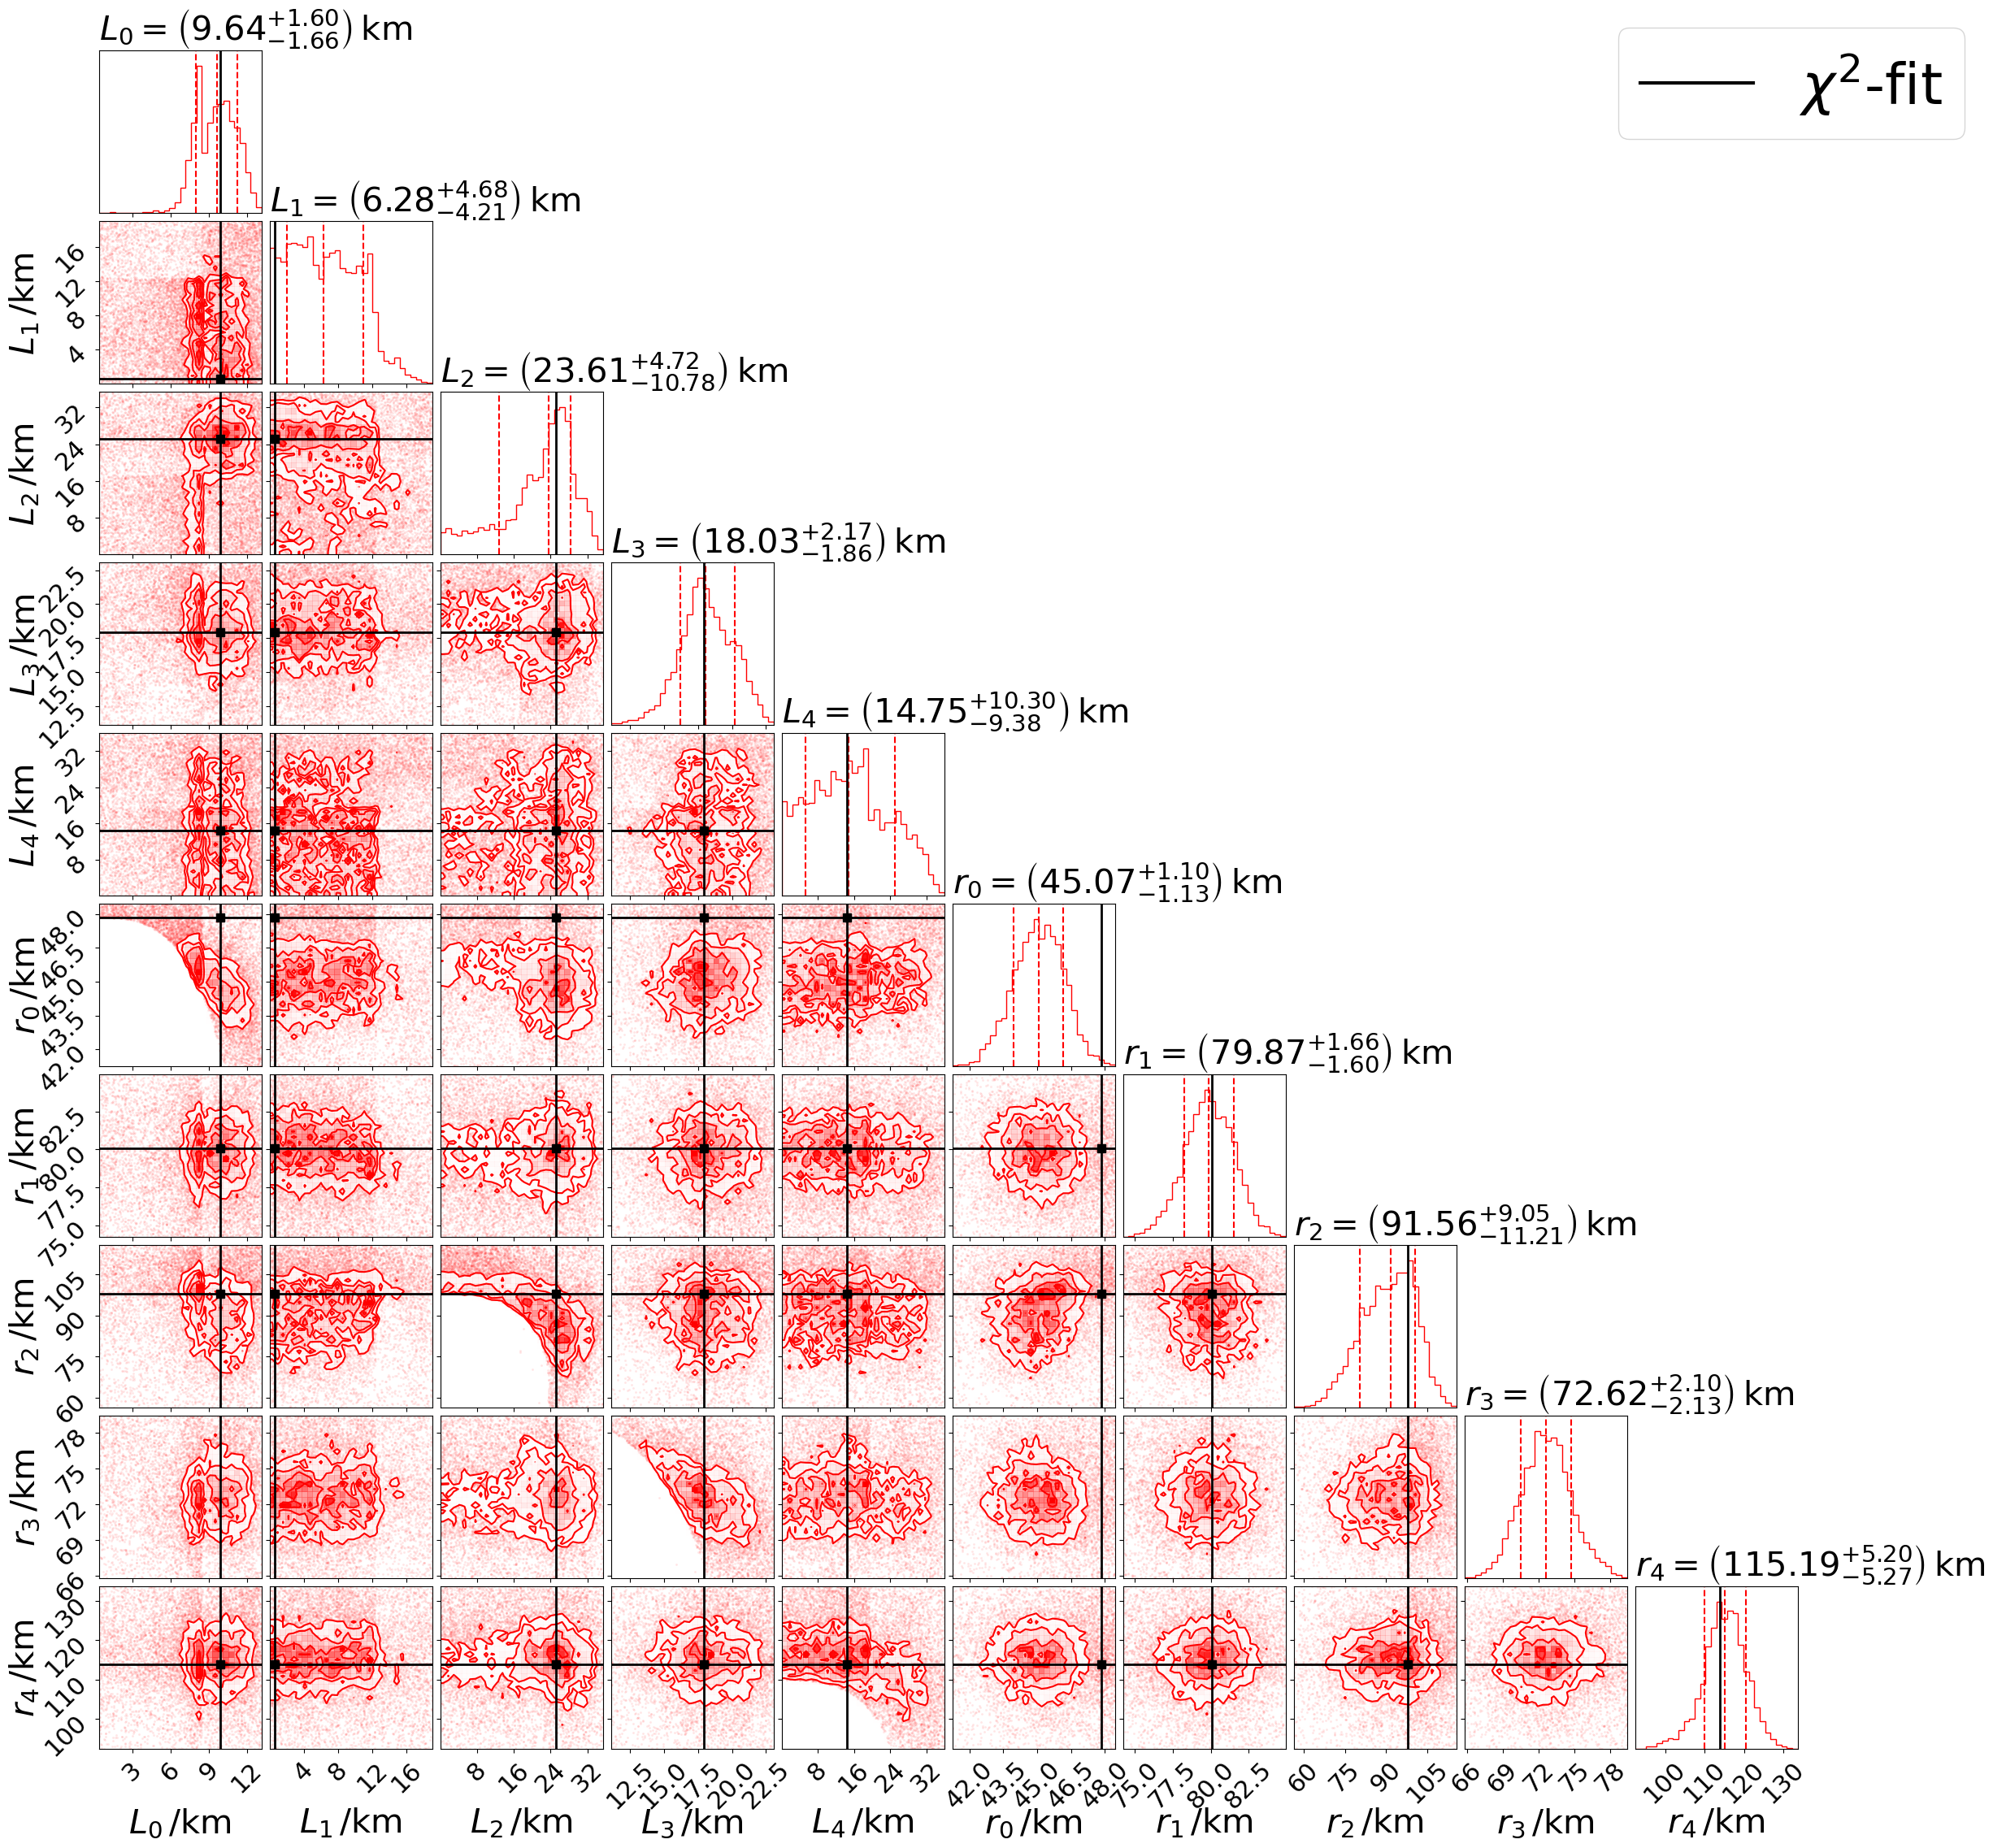

In [12]:
plt.rcParams.update({'font.size': 50,'xtick.labelsize': 22,'ytick.labelsize': 22})
dyn_results = dyn_sampler.results
dyn_samples = dyn_results.samples.copy()
dyn_weights = dyn_results.importance_weights()

fig = corner.corner(
    dyn_samples/1000, weights=dyn_weights, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], bins=30, quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 30},color="red",range=[0.999] * dyn_samples.shape[1],labelpad=0.05
)

dyn_quantiles = np.array([corner.quantile(dyn_samples[:, i],(0.16, 0.5, 0.84), weights=dyn_weights)for i in range(dyn_samples.shape[1])])
dyn_summary = np.column_stack((np.round(dyn_quantiles[:, 1]/1000,2),np.round((dyn_quantiles[:, 0] - dyn_quantiles[:, 1])/1000,2),np.round((dyn_quantiles[:, 2] - dyn_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(ndim, ndim)

for i, label in enumerate(labels):
    dyn_title = (
        rf"${label} = "
        rf"\left({dyn_summary[:,0][i]:.2f}"
        rf"^{{+{dyn_summary[:,2][i]:.2f}}}_{{{dyn_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(dyn_title,fontsize=30,loc="left",)
truths=np.array(L_best+r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
fig.legend(handles=[legend_line])
plt.savefig("../results/h_REG_dynesty_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

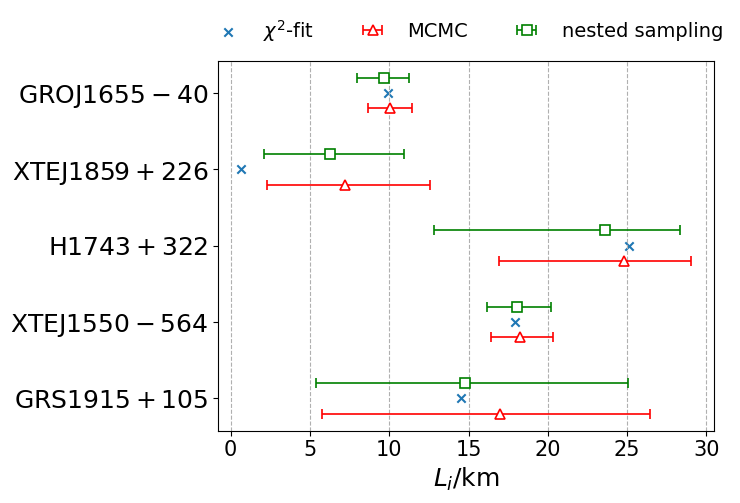

In [13]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(L_best)))
plt.scatter(chi_summary[0:len(L_best)], y,marker="x", label="$\chi^2$-fit")
plt.errorbar(mcmc_summary[:, 0][0:len(L_best)], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3][0:len(L_best)]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
plt.errorbar(dyn_summary[:, 0][0:len(L_best)], y-0.2,xerr=np.abs(dyn_summary[:, 1:3][0:len(L_best)]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)

new_labels = [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
plt.xlabel("$L_i$/km")
plt.legend(loc="lower center",bbox_to_anchor=(0.5, 1),ncol=3,fontsize=14,frameon=False)
plt.grid(axis="x",linestyle="dashed")
plt.gca().invert_yaxis()

plt.savefig("../results/h_REG_L_values_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

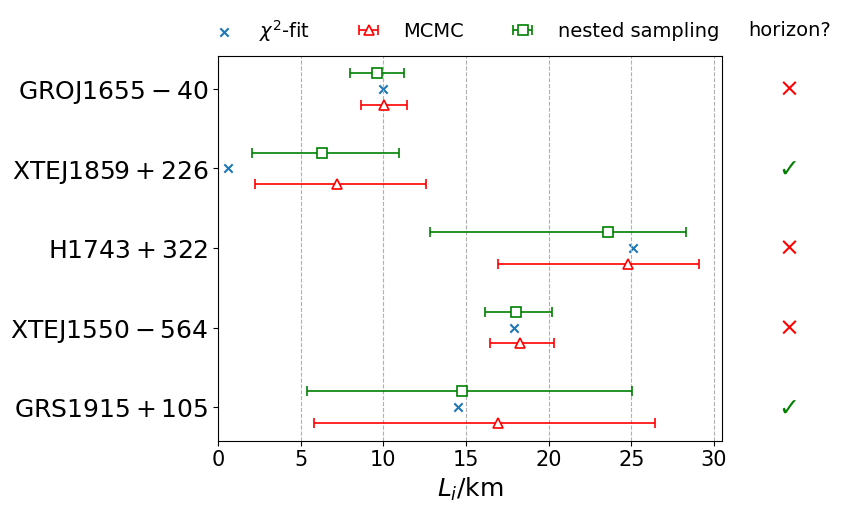

In [19]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(L_best)))
fig = plt.figure(figsize=(8, 5))
gs = fig.add_gridspec(1, 2,width_ratios=[5, 1],wspace=0.05)

ax = fig.add_subplot(gs[0, 0])
ax_table = fig.add_subplot(gs[0, 1], sharey=ax)
ax.scatter(chi_summary[0:len(L_best)], y,marker="x", label="$\chi^2$-fit")
ax.errorbar(mcmc_summary[:, 0][0:len(L_best)], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3][0:len(L_best)]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
ax.errorbar(dyn_summary[:, 0][0:len(L_best)], y-0.2,xerr=np.abs(dyn_summary[:, 1:3][0:len(L_best)]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)

new_labels = [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
ax.set_xlabel("$L_i$/km")

ax.grid(axis="x",linestyle="dashed")
ax.set_xlim(left=0)
ax.invert_yaxis()

ax_table.set_xticks([])

# shared y axis with main plot
ax_table.set_yticks(y)
ax_table.tick_params(axis="y", left=False, labelleft=False)

for i in y:
    symbol = r"$\checkmark$" if mcmc_summary[i,0]<L_BH[i]*10**(-3) else r"$\times$"
    color = "green" if mcmc_summary[i,0]<L_BH[i]*10**(-3) else "red"

    ax_table.text(0.5, i,symbol,ha="center",va="center",fontsize=18,color=color)

for spine in ax_table.spines.values():
    spine.set_visible(False)
    
ax_table.tick_params(axis="x",length=0,labelsize=14,pad=10)

fig.legend(loc="center",bbox_to_anchor=(0.43, 0.93),bbox_transform=fig.transFigure,ncol=3,fontsize=14,frameon=False)

fig.text(0.84, 0.93,"horizon?",transform=fig.transFigure,ha="center",va="center",fontsize=14)

plt.savefig("../results/h_REG_L_values_big_prior_checklist.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

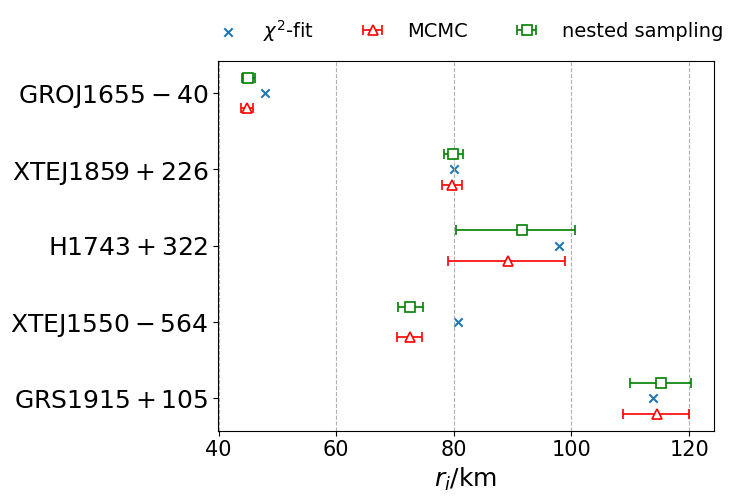

In [15]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(L_best)))
plt.scatter(chi_summary[len(L_best):], y,marker="x", label="$\chi^2$-fit")
plt.errorbar(mcmc_summary[:, 0][len(L_best):], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3][len(L_best):]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
plt.errorbar(dyn_summary[:, 0][len(L_best):], y-0.2,xerr=np.abs(dyn_summary[:, 1:3][len(L_best):]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)

new_labels = [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
plt.xlabel("$r_i$/km")
plt.legend(loc="lower center",bbox_to_anchor=(0.5, 1),ncol=3,fontsize=14,frameon=False)
plt.grid(axis="x",linestyle="dashed")
plt.gca().invert_yaxis()

plt.savefig("../results/h_REG_r_values_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

In [16]:
dyn_values = np.sum(dyn_samples * dyn_weights[:, None],axis=0)
for i in range(len(dyn_values)):
    display(Math(f"{labels[i]} = {dyn_values[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
logZ = dyn_results.logz[-1]
logZ_err = dyn_results.logzerr[-1]

print("log(Z) =", logZ)
print("error of log(Z) =", logZ_err)

log(Z) = -68.80868206582633
error of log(Z) = 0.3719664539129976
